In [ ]:
!pip install -q datasets librosa

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display

from datasets import load_dataset

In [ ]:
!pip show datasets

Name: datasets
Version: 4.8.5
Summary: HuggingFace community-driven open-source library of datasets
Home-page: https://github.com/huggingface/datasets
Author: HuggingFace Inc.
Author-email: thomas@huggingface.co
License: Apache 2.0
Location: /usr/local/lib/python3.13/dist-packages
Requires: dill, filelock, fsspec, httpx, huggingface-hub, multiprocess, numpy, packaging, pandas, pyarrow, pyyaml, requests, tqdm, xxhash
Required-by: torchtune


In [ ]:
from huggingface_hub import list_repo_files

files = list_repo_files("Feanix/gtzan-10-sec", repo_type="dataset")

print("\n".join(files))

.gitattributes
README.md
data/genres.tar.gz
gtzan-10-sec.py
split_audio_files.py


In [ ]:
from huggingface_hub import hf_hub_download

file_path = hf_hub_download(
    repo_id="Feanix/gtzan-10-sec",
    filename="data/genres.tar.gz",
    repo_type="dataset"
)

print("下載完成：")
print(file_path)

data/genres.tar.gz: reconstructing file:   0%|          |  0.00B / 1.22GB            

data/genres.tar.gz: downloading bytes:           |  0.00B            

下載完成：
/root/.cache/huggingface/hub/datasets--Feanix--gtzan-10-sec/snapshots/7cb3eb7b54dc6ef13d63151690177e9b329c3dc3/data/genres.tar.gz


In [ ]:
import tarfile
import os

tar_path = file_path
extract_path = "/content/gtzan_data"

with tarfile.open(tar_path, "r:gz") as tar:
    tar.extractall(extract_path)

print("解壓縮完成！")
print("資料夾內容：")
print(os.listdir(extract_path))

/tmp/ipykernel_3146/1837831773.py:8: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(extract_path)


解壓縮完成！
資料夾內容：
['genres']


In [ ]:
import os

genres_path = "/content/gtzan_data/genres"

print("曲風資料夾：")
print(os.listdir(genres_path))

曲風資料夾：
['hiphop', 'metal', 'reggae', 'classical', 'country', 'jazz', 'blues', 'disco', 'pop', 'rock']


In [ ]:
import os

genres_path = "/content/gtzan_data/genres"

selected_files = []

for genre in ["classical", "hiphop", "rock"]:
    genre_path = os.path.join(genres_path, genre)

    # 取得該曲風的音檔
    audio_files = [
        os.path.join(genre_path, f)
        for f in os.listdir(genre_path)
        if f.lower().endswith((".wav", ".mp3"))
    ]

    # 取前 30 首
    audio_files = sorted(audio_files)[:30]

    for file in audio_files:
        selected_files.append({
            "path": file,
            "genre": genre
        })

print("各曲風數量：")

for genre in ["classical", "hiphop", "rock"]:
    count = sum(1 for x in selected_files if x["genre"] == genre)
    print(f"{genre}: {count}")

print("總資料筆數：", len(selected_files))

各曲風數量：
classical: 30
hiphop: 30
rock: 30
總資料筆數： 90


In [ ]:
import librosa

test_file = selected_files[0]["path"]

y, sr = librosa.load(test_file, sr=None)

print("檔案：", test_file)
print("曲風：", selected_files[0]["genre"])
print("取樣率：", sr)
print("音訊長度：", len(y))
print("秒數：", len(y) / sr)

檔案： /content/gtzan_data/genres/classical/classical.00000_1.wav
曲風： classical
取樣率： 22050
音訊長度： 220500
秒數： 10.0


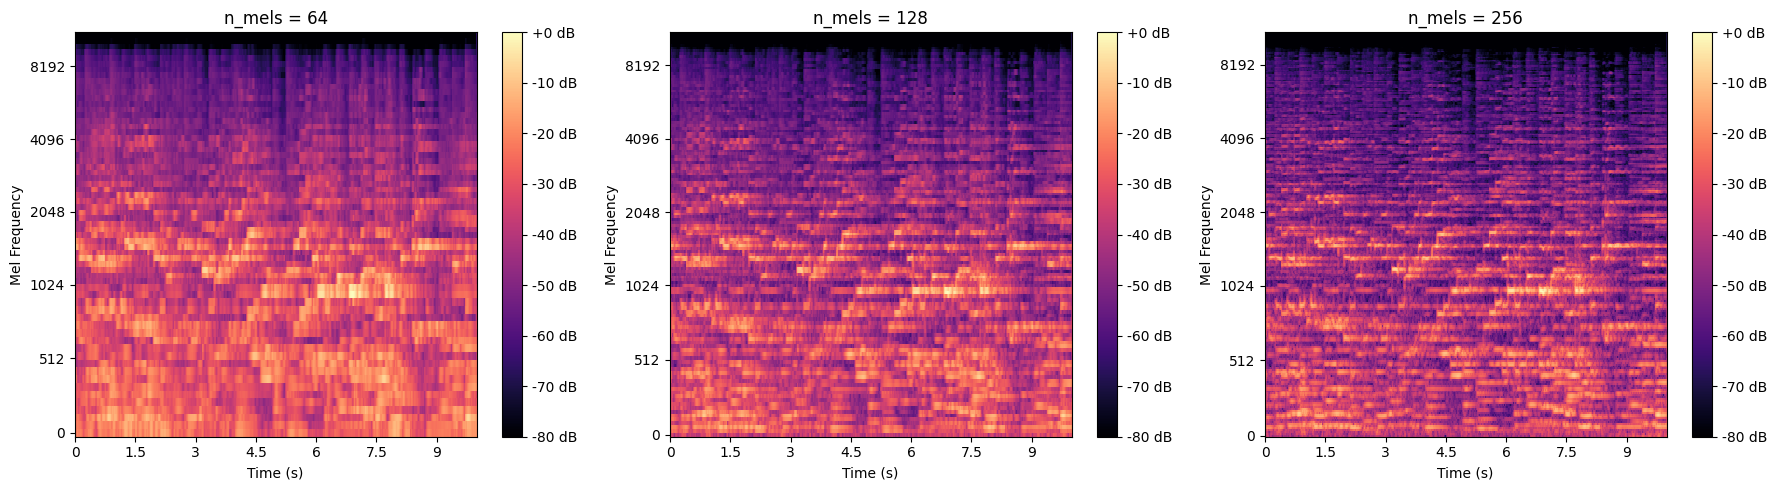

In [ ]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

# 使用同一首音樂
audio_path = selected_files[0]["path"]

# 讀取音訊
y, sr = librosa.load(audio_path, sr=None)

# 三種 n_mels 設定
n_mels_list = [64, 128, 256]

plt.figure(figsize=(18, 5))

for i, n_mels in enumerate(n_mels_list):

    # 建立 Mel 頻譜圖
    mel_spec = librosa.feature.melspectrogram(
        y=y,
        sr=sr,
        n_mels=n_mels
    )

    # 轉換成 dB
    mel_spec_db = librosa.power_to_db(
        mel_spec,
        ref=np.max
    )

    # 畫圖
    plt.subplot(1, 3, i + 1)

    librosa.display.specshow(
        mel_spec_db,
        sr=sr,
        x_axis="time",
        y_axis="mel"
    )

    plt.title(f"n_mels = {n_mels}")
    plt.xlabel("Time (s)")
    plt.ylabel("Mel Frequency")
    plt.colorbar(format="%+2.0f dB")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import librosa
import librosa.feature
import cv2

def audio_to_mel_image(audio_path, n_mels):
    # 讀取音訊
    y, sr = librosa.load(audio_path, sr=None)

    # 建立 Mel 頻譜圖
    mel_spec = librosa.feature.melspectrogram(
        y=y,
        sr=sr,
        n_mels=n_mels
    )

    # 轉換成 dB
    mel_spec_db = librosa.power_to_db(
        mel_spec,
        ref=np.max
    )

    # 調整成 128 × 128
    mel_image = cv2.resize(
        mel_spec_db,
        (128, 128)
    )

    return mel_image

In [ ]:
test_mel = audio_to_mel_image(
    selected_files[0]["path"],
    n_mels=128
)

print("Mel 頻譜圖形狀：", test_mel.shape)

Mel 頻譜圖形狀： (128, 128)


In [ ]:
X_128 = []
y_128 = []

label_map = {
    "classical": 0,
    "hiphop": 1,
    "rock": 2
}

for item in selected_files:
    mel_image = audio_to_mel_image(
        item["path"],
        n_mels=128
    )

    X_128.append(mel_image)
    y_128.append(label_map[item["genre"]])

# 轉成 NumPy 陣列
X_128 = np.array(X_128)
y_128 = np.array(y_128)

# 增加 CNN 所需的 channel 維度
X_128 = X_128[..., np.newaxis]

print("X_128 shape:", X_128.shape)
print("y_128 shape:", y_128.shape)
print("標籤數量：")
print("classical:", np.sum(y_128 == 0))
print("hiphop:", np.sum(y_128 == 1))
print("rock:", np.sum(y_128 == 2))

X_128 shape: (90, 128, 128, 1)
y_128 shape: (90,)
標籤數量：
classical: 30
hiphop: 30
rock: 30


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_128,
    y_128,
    test_size=0.2,
    random_state=42,
    stratify=y_128
)

print("訓練集：", X_train.shape)
print("測試集：", X_test.shape)

print("\n訓練集各類別數量：")
print("classical:", np.sum(y_train == 0))
print("hiphop:", np.sum(y_train == 1))
print("rock:", np.sum(y_train == 2))

print("\n測試集各類別數量：")
print("classical:", np.sum(y_test == 0))
print("hiphop:", np.sum(y_test == 1))
print("rock:", np.sum(y_test == 2))

訓練集： (72, 128, 128, 1)
測試集： (18, 128, 128, 1)

訓練集各類別數量：
classical: 24
hiphop: 24
rock: 24

測試集各類別數量：
classical: 6
hiphop: 6
rock: 6


In [ ]:
import tensorflow as tf
from tensorflow.keras import models, layers

print("TensorFlow 版本：", tf.__version__)

TensorFlow 版本： 2.21.0


In [ ]:
model = models.Sequential([

    # 第一層卷積
    layers.Conv2D(
        32,
        (3, 3),
        activation="relu",
        input_shape=(128, 128, 1)
    ),
    layers.MaxPooling2D((2, 2)),

    # 第二層卷積
    layers.Conv2D(
        64,
        (3, 3),
        activation="relu"
    ),
    layers.MaxPooling2D((2, 2)),

    # 第三層卷積
    layers.Conv2D(
        128,
        (3, 3),
        activation="relu"
    ),
    layers.MaxPooling2D((2, 2)),

    # 展平
    layers.Flatten(),

    # 全連接層
    layers.Dense(
        128,
        activation="relu"
    ),

    # 輸出層：3 種曲風
    layers.Dense(
        3,
        activation="softmax"
    )
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,451 (12.61 MB)

 Trainable params: 3,304,451 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

Epoch 1/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 13s 2s/step - accuracy: 0.3158 - loss: 56.1564 - val_accuracy: 0.2667 - val_loss: 15.7019
Epoch 2/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.3684 - loss: 7.0591 - val_accuracy: 0.4000 - val_loss: 1.5199
Epoch 3/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.2982 - loss: 1.7527 - val_accuracy: 0.4000 - val_loss: 1.0611
Epoch 4/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.3333 - loss: 1.1694 - val_accuracy: 0.4000 - val_loss: 1.1323
Epoch 5/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.3509 - loss: 1.1080 - val_accuracy: 0.3333 - val_loss: 1.1295
Epoch 6/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.3684 - loss: 1.1086 - val_accuracy: 0.3333 - val_loss: 1.0871
Epoch 7/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.4211 - loss: 1.0615 - val_accuracy: 0.3333 - val_loss: 1.0750
Epoch 8/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.3509 - loss: 1.0415 - val_accuracy: 0.6667 - val_loss: 1.0240

In [ ]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("測試集 Loss：", test_loss)
print("測試集 Accuracy：", test_accuracy)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 981ms/step - accuracy: 0.6111 - loss: 0.6994
測試集 Loss： 0.6994096040725708
測試集 Accuracy： 0.6111111044883728


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

# 使用訓練完成的模型進行預測
y_pred_prob = model.predict(X_test)

# 取得每筆資料預測機率最高的類別
y_pred = np.argmax(y_pred_prob, axis=1)

# 建立混淆矩陣
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1, 2]
)

print("混淆矩陣：")
print(cm)

print("\n分類報告：")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1, 2],
    target_names=["classical", "hiphop", "rock"],
    zero_division=0
))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 417ms/step
混淆矩陣：
[[4 2 0]
 [1 5 0]
 [0 4 2]]

分類報告：
              precision    recall  f1-score   support

   classical       0.80      0.67      0.73         6
      hiphop       0.45      0.83      0.59         6
        rock       1.00      0.33      0.50         6

    accuracy                           0.61        18
   macro avg       0.75      0.61      0.61        18
weighted avg       0.75      0.61      0.61        18



In [ ]:

# ===== n_mels = 64 實驗 =====

import numpy as np
import tensorflow as tf
from tensorflow.keras import models, layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

# 1. 建立 n_mels = 64 的資料
X_64 = []
y_64 = []

for item in selected_files:
    mel_image = audio_to_mel_image(
        item["path"],
        n_mels=64
    )
    X_64.append(mel_image)
    y_64.append(label_map[item["genre"]])

X_64 = np.array(X_64)[..., np.newaxis]
y_64 = np.array(y_64)

print("X_64 shape:", X_64.shape)

# 2. 使用相同的資料切分條件
X_train_64, X_test_64, y_train_64, y_test_64 = train_test_split(
    X_64,
    y_64,
    test_size=0.2,
    random_state=42,
    stratify=y_64
)

# 3. 建立相同架構的 CNN
tf.keras.backend.clear_session()

model_64 = models.Sequential([
    layers.Input(shape=(128, 128, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(3, activation="softmax")
])

model_64.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 4. 訓練模型
history_64 = model_64.fit(
    X_train_64,
    y_train_64,
    epochs=20,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

# 5. 評估測試集
loss_64, acc_64 = model_64.evaluate(
    X_test_64,
    y_test_64,
    verbose=1
)

print("\nn_mels = 64")
print("測試集 Loss：", loss_64)
print("測試集 Accuracy：", acc_64)
print("測試集正確數：", round(acc_64 * len(y_test_64)), "/", len(y_test_64))

# 6. 混淆矩陣與分類報告
pred_64 = np.argmax(model_64.predict(X_test_64), axis=1)

print("\n混淆矩陣：")
print(confusion_matrix(y_test_64, pred_64, labels=[0, 1, 2]))

print("\n分類報告：")
print(classification_report(
    y_test_64,
    pred_64,
    labels=[0, 1, 2],
    target_names=["classical", "hiphop", "rock"],
    zero_division=0
))


X_64 shape: (90, 128, 128, 1)
Epoch 1/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 697ms/step - accuracy: 0.2105 - loss: 37.3073 - val_accuracy: 0.3333 - val_loss: 8.4668
Epoch 2/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.3158 - loss: 4.2112 - val_accuracy: 0.3333 - val_loss: 2.0908
Epoch 3/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.4561 - loss: 1.3702 - val_accuracy: 0.2667 - val_loss: 1.7681
Epoch 4/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.4737 - loss: 1.1558 - val_accuracy: 0.4000 - val_loss: 0.9220
Epoch 5/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.4386 - loss: 0.8778 - val_accuracy: 0.7333 - val_loss: 0.8399
Epoch 6/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.5088 - loss: 1.2132 - val_accuracy: 0.6000 - val_loss: 1.3020
Epoch 7/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.7018 - loss: 0.8625 - val_accuracy: 0.4000 - val_loss: 0.8714
Epoch 8/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.6667 - loss: 0.7105 - val_accu

In [ ]:

# ===== n_mels = 256 實驗 =====

X_256 = []
y_256 = []

for item in selected_files:
    mel_image = audio_to_mel_image(
        item["path"],
        n_mels=256
    )
    X_256.append(mel_image)
    y_256.append(label_map[item["genre"]])

X_256 = np.array(X_256)[..., np.newaxis]
y_256 = np.array(y_256)

print("X_256 shape:", X_256.shape)

# 使用相同的資料切分條件
X_train_256, X_test_256, y_train_256, y_test_256 = train_test_split(
    X_256,
    y_256,
    test_size=0.2,
    random_state=42,
    stratify=y_256
)

# 建立相同架構的 CNN
tf.keras.backend.clear_session()

model_256 = models.Sequential([
    layers.Input(shape=(128, 128, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(3, activation="softmax")
])

model_256.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 訓練模型
history_256 = model_256.fit(
    X_train_256,
    y_train_256,
    epochs=20,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

# 評估測試集
loss_256, acc_256 = model_256.evaluate(
    X_test_256,
    y_test_256,
    verbose=1
)

print("\nn_mels = 256")
print("測試集 Loss：", loss_256)
print("測試集 Accuracy：", acc_256)
print("測試集正確數：", round(acc_256 * len(y_test_256)), "/", len(y_test_256))

# 混淆矩陣與分類報告
pred_256 = np.argmax(model_256.predict(X_test_256), axis=1)

print("\n混淆矩陣：")
print(confusion_matrix(y_test_256, pred_256, labels=[0, 1, 2]))

print("\n分類報告：")
print(classification_report(
    y_test_256,
    pred_256,
    labels=[0, 1, 2],
    target_names=["classical", "hiphop", "rock"],
    zero_division=0
))


X_256 shape: (90, 128, 128, 1)
Epoch 1/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 686ms/step - accuracy: 0.2982 - loss: 51.3856 - val_accuracy: 0.2667 - val_loss: 6.7735
Epoch 2/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.2982 - loss: 3.4282 - val_accuracy: 0.3333 - val_loss: 1.2255
Epoch 3/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.5263 - loss: 1.0802 - val_accuracy: 0.3333 - val_loss: 1.4968
Epoch 4/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.2105 - loss: 1.3512 - val_accuracy: 0.4000 - val_loss: 1.4415
Epoch 5/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.3684 - loss: 1.3560 - val_accuracy: 0.4000 - val_loss: 1.0470
Epoch 6/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.3509 - loss: 1.0276 - val_accuracy: 0.4000 - val_loss: 0.9674
Epoch 7/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.4561 - loss: 0.9528 - val_accuracy: 0.4667 - val_loss: 0.9915
Epoch 8/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.7368 - loss: 0.7781 - val_acc

In [ ]:
print("音訊筆數：", len(selected_files))
print("資料形狀：", X_128.shape)
print("標籤形狀：", y_128.shape)
print("CNN 模型架構：")
model.summary()

音訊筆數： 90
資料形狀： (90, 128, 128, 1)
標籤形狀： (90,)
CNN 模型架構：


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,913,355 (37.82 MB)

 Trainable params: 3,304,451 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 6,608,904 (25.21 MB)

In [ ]:

import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras import models, layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

# =========================
# 1. 實驗設定
# =========================

n_mels_list = [64, 128, 256]
seeds = [42, 123, 2026, 3407]

results = []
confusion_matrices = {}

# 固定資料切分，讓三種設定使用相同的訓練集與測試集
# 注意：資料切分固定，不代表每次模型訓練都會得到相同結果。

# =========================
# 2. 建立 CNN
# =========================

def build_cnn():
    model = models.Sequential([
        layers.Input(shape=(128, 128, 1)),

        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(3, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

# =========================
# 3. 產生各種 n_mels 的資料
# =========================

X_by_mels = {}

for n_mels in n_mels_list:
    print(f"\n正在製作 n_mels = {n_mels} 的特徵圖")

    X_list = []
    y_list = []

    for item in selected_files:
        mel_image = audio_to_mel_image(
            item["path"],
            n_mels=n_mels
        )

        X_list.append(mel_image)
        y_list.append(label_map[item["genre"]])

    X = np.array(X_list, dtype=np.float32)[..., np.newaxis]
    y = np.array(y_list, dtype=np.int64)

    X_by_mels[n_mels] = (X, y)

    print("資料形狀：", X.shape)

# =========================
# 4. 執行 12 次訓練
# =========================

for n_mels in n_mels_list:
    X, y = X_by_mels[n_mels]

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    for seed in seeds:
        print("\n" + "=" * 50)
        print(f"n_mels = {n_mels} | seed = {seed}")
        print("=" * 50)

        # 設定 Python、NumPy、TensorFlow 的隨機種子
        random.seed(seed)
        np.random.seed(seed)
        tf.keras.utils.set_random_seed(seed)

        # 清除前一個模型，降低模型狀態互相干擾
        tf.keras.backend.clear_session()

        model = build_cnn()

        model.fit(
            X_train,
            y_train,
            epochs=20,
            batch_size=16,
            validation_split=0.2,
            verbose=0
        )

        loss, accuracy = model.evaluate(
            X_test,
            y_test,
            verbose=0
        )

        y_pred = np.argmax(
            model.predict(X_test, verbose=0),
            axis=1
        )

        cm = confusion_matrix(
            y_test,
            y_pred,
            labels=[0, 1, 2]
        )

        results.append({
            "n_mels": n_mels,
            "seed": seed,
            "test_loss": float(loss),
            "accuracy": float(accuracy),
            "correct": int(np.sum(y_pred == y_test)),
            "total": len(y_test)
        })

        confusion_matrices[(n_mels, seed)] = cm

        print(f"Test Loss: {loss:.4f}")
        print(f"Test Accuracy: {accuracy * 100:.2f}%")
        print("混淆矩陣：")
        print(cm)

# =========================
# 5. 整理 12 次實驗結果
# =========================

results_df = pd.DataFrame(results)
results_df["accuracy_percent"] = results_df["accuracy"] * 100

print("\n===== 各次實驗結果 =====")
print(
    results_df[
        ["n_mels", "seed", "test_loss",
         "accuracy_percent", "correct", "total"]
    ].to_string(index=False)
)

# =========================
# 6. 計算平均值與標準差
# =========================

summary_df = results_df.groupby("n_mels").agg(
    平均準確率=("accuracy_percent", "mean"),
    準確率標準差=("accuracy_percent", "std"),
    平均Loss=("test_loss", "mean"),
    Loss標準差=("test_loss", "std")
).reset_index()

print("\n===== 各 n_mels 的統計摘要 =====")
print(summary_df.round(2).to_string(index=False))

# 儲存結果，方便後續整理報告
results_df.to_csv(
    "mel_experiment_all_runs.csv",
    index=False,
    encoding="utf-8-sig"
)

summary_df.to_csv(
    "mel_experiment_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n已儲存：mel_experiment_all_runs.csv")
print("已儲存：mel_experiment_summary.csv")



正在製作 n_mels = 64 的特徵圖
資料形狀： (90, 128, 128, 1)

正在製作 n_mels = 128 的特徵圖
資料形狀： (90, 128, 128, 1)

正在製作 n_mels = 256 的特徵圖
資料形狀： (90, 128, 128, 1)

n_mels = 64 | seed = 42
Test Loss: 0.6933
Test Accuracy: 55.56%
混淆矩陣：
[[1 0 5]
 [0 4 2]
 [0 1 5]]

n_mels = 64 | seed = 123


Test Loss: 0.7748
Test Accuracy: 88.89%
混淆矩陣：
[[6 0 0]
 [0 6 0]
 [0 2 4]]

n_mels = 64 | seed = 2026


Test Loss: 1.0924
Test Accuracy: 77.78%
混淆矩陣：
[[4 0 2]
 [0 6 0]
 [0 2 4]]

n_mels = 64 | seed = 3407
Test Loss: 0.7610
Test Accuracy: 88.89%
混淆矩陣：
[[6 0 0]
 [0 6 0]
 [0 2 4]]

n_mels = 128 | seed = 42
Test Loss: 0.2813
Test Accuracy: 94.44%
混淆矩陣：
[[6 0 0]
 [0 6 0]
 [0 1 5]]

n_mels = 128 | seed = 123
Test Loss: 0.2727
Test Accuracy: 88.89%
混淆矩陣：
[[6 0 0]
 [0 5 1]
 [1 0 5]]

n_mels = 128 | seed = 2026
Test Loss: 0.7778
Test Accuracy: 88.89%
混淆矩陣：
[[6 0 0]
 [0 6 0]
 [0 2 4]]

n_mels = 128 | seed = 3407
Test Loss: 0.1652
Test Accuracy: 94.44%
混淆矩陣：
[[6 0 0]
 [0 6 0]
 [0 1 5]]

n_mels = 256 | seed = 42
Test Loss: 0.5673
Test Accuracy: 72.22%
混淆矩陣：
[[6 0 0]
 [0 6 0]
 [1 4 1]]

n_mels = 256 | seed = 123
Test Loss: 0.6062
Test Accuracy: 83.33%
混淆矩陣：
[[6 0 0]
 [0 6 0]
 [0 3 3]]

n_mels = 256 | seed = 2026
Test Loss: 0.3573
Test Accuracy: 88.89%
混淆矩陣：
[[6 0 0]
 [0 6 0]
 [1 1 4]]

n_mels = 256 | seed = 3407
Test Loss: 0.3629
Test Accuracy: 88.89%
混淆矩陣：
[[6 0 0]
 [0 6 0]
 [0 2 4]]

===== 各次實驗結果 =